In [9]:
import matplotlib.pyplot as plt
from photutils.profiles import RadialProfile
from astropy.io import fits
import os
import numpy as np

In [11]:
#hdu_list1 = fits.open('jupyter/daschlab__hd_175893/cutouts/05115_mf20918m0s0.fits')
#hdu_list1 = fits.open('jupyter/daschlab__hd_175893/cutouts/03281_mf06425m0s0.fits')
#hdu_list1 = fits.open('jupyter/daschlab__hd_175893/cutouts/05504_mf25123m0s0.fits')
hdu_list1 = fits.open('jupyter/daschlab__hd_175893/cutouts/03574_am15869m0s0.fits')

positions = [(418.,418.),(187,242),(108.,491.)]

yr = np.zeros(3)
 
bkg=3500.

image_data=hdu_list1[0].data
data=image_data-bkg
#xycen=(406.74,417.88)
xycen=(418.-5,418.)
edge_radii = np.arange(25)
rp = RadialProfile(data, xycen, edge_radii, mask=None)
rp.gaussian_fit
print('HD 175893 ',f"{rp.gaussian_fwhm:.2f}")


#xycen=(406.74,417.88)
xycen=(187-5,242)
#edge_radii = np.arange(30)
rp = RadialProfile(data, xycen, edge_radii, mask=None)
rp.gaussian_fit
print('10.97 ',f"{rp.gaussian_fwhm:.2f}")
yr[0]=rp.gaussian_fwhm



#xycen=(406.74,417.88)
xycen=(108.-5,491.)
#edge_radii = np.arange(25)
rp = RadialProfile(data, xycen, edge_radii, mask=None)
rp.gaussian_fit
print('12.20 ',f"{rp.gaussian_fwhm:.2f}")
yr[1]=rp.gaussian_fwhm


#image_data = hdu_list4[0].data
#data=image_data-bkg
#xycen=(406.74,417.88)
xycen=(545.-5,142.)
edge_radii = np.arange(25)
rp = RadialProfile(data, xycen, edge_radii, mask=None)
rp.gaussian_fit
print('12.44 ',f"{rp.gaussian_fwhm:.2f}")
yr[2]=rp.gaussian_fwhm

HD 175893  23.89
10.97  24.45
12.20  25.10
12.44  24.66


In [13]:
import pandas as pd # for data manipulation
import numpy as np # for data manipulation
from sklearn.linear_model import LinearRegression # to build a LR model for comparison
import plotly.graph_objects as go # for data visualization
import plotly.express as px # for data visualization 
import statsmodels.api as sm # to build a LOWESS model
from scipy.interpolate import interp1d # for interpolation of new data points

In [19]:
xr=np.array((10.97,12.20,12.44))
yr=np.array([27.97030674, 24.38283113, 23.47197037])
yrlog=np.log10(yr)

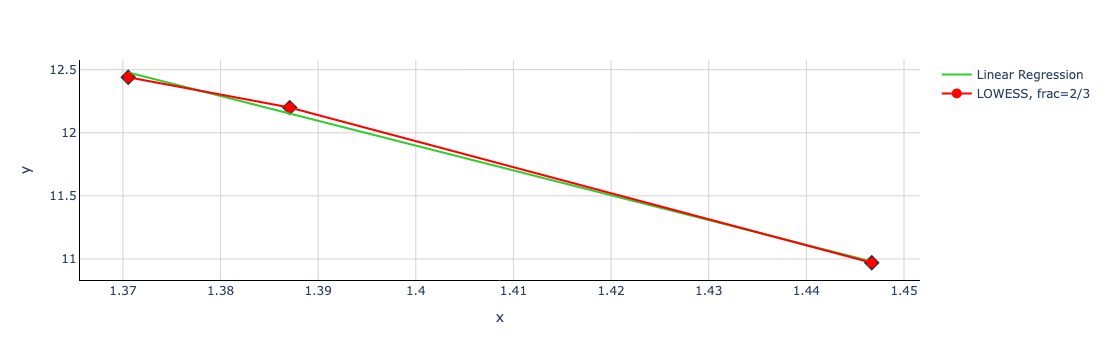

In [21]:
# ------- Select variables -------
# x values for Linear Regression
X=yrlog.reshape(-1,1) # Note, we need X to be a 2D array, hence reshape
# x values for LOWESS
x=yrlog
# y values for both
y=xr

# ------- Linear Regression -------
# Define and fit the model
model1 = LinearRegression()
LR = model1.fit(X, y)

# Predict a few points with Linear Regression model for the grpah
# Create 20 evenly spaced points from smallest X to largest X
x_range = np.linspace(X.min(), X.max(), 20) 
# Predict y values for our set of X values
y_range = model1.predict(x_range.reshape(-1, 1))

# ------- LOWESS -------
# Define a model
lowess = sm.nonparametric.lowess

# Generate y_hat values using lowess, try a couple values for hyperparameters
y_hat1 = lowess(y, x) # note, default frac=2/3
y_hat2 = lowess(y, x, frac=1/5)
#With fitting done, let us draw simple linear regression and LOWESS lines on the graph.

# Create a scatter plot
#plt.xlim( (5,35) )
#plt.ylim( (17,9))
#plt.yscale("log")
#plt.xscale("log")
fig = px.scatter(x=yrlog, y=xr, 
                 opacity=0.8, color_discrete_sequence=['black'])
#, log_x=True

# Add the prediction line
fig.add_traces(go.Scatter(x=x_range, y=y_range, name='Linear Regression', line=dict(color='limegreen')))
fig.add_traces(go.Scatter(x=y_hat1[:,0], y=y_hat1[:,1], name='LOWESS, frac=2/3', line=dict(color='red')))
#fig.add_traces(go.Scatter(x=y_hat2[:,0], y=y_hat2[:,1], name='LOWESS, frac=1/5', line=dict(color='orange')))

# Change chart background color
fig.update_layout(dict(plot_bgcolor = 'white'))

# Update axes lines
fig.update_xaxes(showgrid=True, gridwidth=1, gridcolor='lightgrey', 
                 zeroline=True, zerolinewidth=1, zerolinecolor='lightgrey', 
                 showline=True, linewidth=1, linecolor='black')

fig.update_yaxes(showgrid=True, gridwidth=1, gridcolor='lightgrey', 
                 zeroline=True, zerolinewidth=1, zerolinecolor='lightgrey', 
                 showline=True, linewidth=1, linecolor='black')

# Set figure title
#fig.update_layout(title=dict(text="House Price Based on Distance from the Nearest MRT with Model Predictions", 
                             #font=dict(color='black')))

fig.update_traces(
    marker=dict(size=5, symbol="diamond", line=dict(width=2, color="Black")),
    selector=dict(mode="markers"),
)

# Update marker size
fig.update_traces(marker=dict(size=10))
#fig.update_layout(yaxis_range=[11,6])

fig.show()

In [23]:
# ------- Define interploation functions -------
# Linear - draws a line between the two nearest points and calculates y value based on the slope of that line
f_linear = interp1d(y_hat1[:,0], y=y_hat1[:,1], bounds_error=False, kind='linear', fill_value='extrapolate') 
# Nearest - finds the nearest available point and takes its y value
f_nearest = interp1d(y_hat1[:,0], y=y_hat1[:,1], bounds_error=False, kind='nearest', fill_value='extrapolate') 

# Create a new set of points with x values 
xnew = [np.log10(30.13)]

# Find y values based on the two different interpolation methods
ynew_linear = f_linear(xnew)
ynew_nearest = f_nearest(xnew)

# Print results
print(ynew_linear)
print(ynew_nearest)
print(xnew)

[10.30351325]
[10.97]
[1.478999131673357]
